# Level 2 — Task 2: Cuisine Combination

### Most Common Cuisine Combinations & Their Ratings

This dataset contains 9,551 restaurant listings scraped from a Zomato-style
platform, covering cuisine type, cost, ratings, and location across multiple
cities and countries.

**Business question:** Which cuisines do restaurants usually serve together, and
do certain combinations earn higher ratings than others?

**Objectives:**
1. Identify the most common combinations of cuisines in the dataset.
2. Determine if certain cuisine combinations tend to have higher ratings.

## 1. Dataset Overview

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from itertools import combinations
from collections import Counter

### Note: filename has a trailing space as saved in the data folder

In [2]:
df = pd.read_csv("../../data/Dataset .csv")
df.head()

,Restaurant ID,Restaurant Name,Country Code,City,Address,Locality,Locality Verbose,Longitude,Latitude,Cuisines,...,Currency,Has Table booking,Has Online delivery,Is delivering now,Switch to order menu,Price range,Aggregate rating,Rating color,Rating text,Votes
0,6317637,Le Petit Souffle,162,Makati City,"Third Floor, Century City Mall, Kalayaan Avenu...","Century City Mall, Poblacion, Makati City","Century City Mall, Poblacion, Makati City, Mak...",121.027535,14.565443,"French, Japanese, Desserts",...,Botswana Pula(P),Yes,No,No,No,3,4.8,Dark Green,Excellent,314
1,6304287,Izakaya Kikufuji,162,Makati City,"Little Tokyo, 2277 Chino Roces Avenue, Legaspi...","Little Tokyo, Legaspi Village, Makati City","Little Tokyo, Legaspi Village, Makati City, Ma...",121.014101,14.553708,Japanese,...,Botswana Pula(P),Yes,No,No,No,3,4.5,Dark Green,Excellent,591
2,6300002,Heat - Edsa Shangri-La,162,Mandaluyong City,"Edsa Shangri-La, 1 Garden Way, Ortigas, Mandal...","Edsa Shangri-La, Ortigas, Mandaluyong City","Edsa Shangri-La, Ortigas, Mandaluyong City, Ma...",121.056831,14.581404,"Seafood, Asian, Filipino, Indian",...,Botswana Pula(P),Yes,No,No,No,4,4.4,Green,Very Good,270
3,6318506,Ooma,162,Mandaluyong City,"Third Floor, Mega Fashion Hall, SM Megamall, O...","SM Megamall, Ortigas, Mandaluyong City","SM Megamall, Ortigas, Mandaluyong City, Mandal...",121.056475,14.585318,"Japanese, Sushi",...,Botswana Pula(P),No,No,No,No,4,4.9,Dark Green,Excellent,365
4,6314302,Sambo Kojin,162,Mandaluyong City,"Third Floor, Mega Atrium, SM Megamall, Ortigas...","SM Megamall, Ortigas, Mandaluyong City","SM Megamall, Ortigas, Mandaluyong City, Mandal...",121.057508,14.584450,"Japanese, Korean",...,Botswana Pula(P),Yes,No,No,No,4,4.8,Dark Green,Excellent,229


In [3]:
df.shape

(9551, 21)

## 2. Data Quality Assessment

In [4]:
print("Missing Cuisines values:", df["Cuisines"].isna().sum())
print("Missing Aggregate rating values:", df["Aggregate rating"].isna().sum())

unrated = (df["Aggregate rating"] == 0).sum()
print(f"Unrated restaurants (rating = 0): {unrated} ({unrated / len(df) * 100:.2f}%)")

Missing Cuisines values: 9
Missing Aggregate rating values: 0
Unrated restaurants (rating = 0): 2148 (22.49%)


Only 9 restaurants have no cuisine listed, so they are excluded from this task.
A rating of `0` means **"Not rated"**, not a terrible restaurant, so unrated
restaurants are excluded when ratings are compared (Section 5).

## 3. Preparing the Cuisine Combinations

The `Cuisines` column stores several cuisines in one text field
(e.g. `"Chinese, North Indian"`). Each restaurant's cuisines are split,
cleaned, de-duplicated and **sorted alphabetically**, so that
`"North Indian, Chinese"` and `"Chinese, North Indian"` count as the same
combination.

In [5]:
df_c = df.dropna(subset=["Cuisines"]).copy()

df_c["Cuisine List"] = df_c["Cuisines"].apply(lambda s: sorted(set(c.strip() for c in s.split(","))))
df_c["Num Cuisines"] = df_c["Cuisine List"].str.len()
df_c["Combination"] = df_c["Cuisine List"].apply(lambda l: ", ".join(l))

print("Rows used:", len(df_c))
df_c[["Restaurant Name", "Cuisines", "Combination", "Num Cuisines"]].head()

Rows used: 9542


,Restaurant Name,Cuisines,Combination,Num Cuisines
0,Le Petit Souffle,"French, Japanese, Desserts","Desserts, French, Japanese",3
1,Izakaya Kikufuji,Japanese,Japanese,1
2,Heat - Edsa Shangri-La,"Seafood, Asian, Filipino, Indian","Asian, Filipino, Indian, Seafood",4
3,Ooma,"Japanese, Sushi","Japanese, Sushi",2
4,Sambo Kojin,"Japanese, Korean","Japanese, Korean",2


In [6]:
num_dist = df_c["Num Cuisines"].value_counts().sort_index()

num_cuisines_table = pd.DataFrame({
    "Cuisines Listed": num_dist.index,
    "Restaurant Count": num_dist.values,
    "Percentage": (num_dist.values / len(df_c) * 100).round(2),
})
num_cuisines_table

,Cuisines Listed,Restaurant Count,Percentage
0,1,3394,35.57
1,2,3447,36.12
2,3,1839,19.27
3,4,582,6.10
4,5,164,1.72
5,6,74,0.78
6,7,28,0.29
7,8,14,0.15


In [7]:
multi = df_c[df_c["Num Cuisines"] > 1].copy()

print(f"Restaurants with 2+ cuisines: {len(multi):,} ({len(multi) / len(df_c) * 100:.2f}%)")
print("Unique multi-cuisine combinations:", multi["Combination"].nunique())

Restaurants with 2+ cuisines: 6,148 (64.43%)
Unique multi-cuisine combinations: 1245


## 4. Most Common Cuisine Combinations

In [8]:
combo_counts = multi["Combination"].value_counts()

top_combos = pd.DataFrame({
    "Cuisine Combination": combo_counts.head(10).index,
    "Restaurant Count": combo_counts.head(10).values,
    "% of Multi-Cuisine Restaurants": (combo_counts.head(10).values / len(multi) * 100).round(2),
})
top_combos

,Cuisine Combination,Restaurant Count,% of Multi-Cuisine Restaurants
0,"Chinese, North Indian",616,10.02
1,"Mughlai, North Indian",395,6.42
2,"Chinese, Mughlai, North Indian",306,4.98
3,"Bakery, Desserts",182,2.96
4,"Chinese, Fast Food",159,2.59
5,"Fast Food, Pizza",142,2.31
6,"Chinese, North Indian, South Indian",137,2.23
7,"Mithai, Street Food",134,2.18
8,"Fast Food, North Indian",120,1.95
9,"Bakery, Fast Food",117,1.90


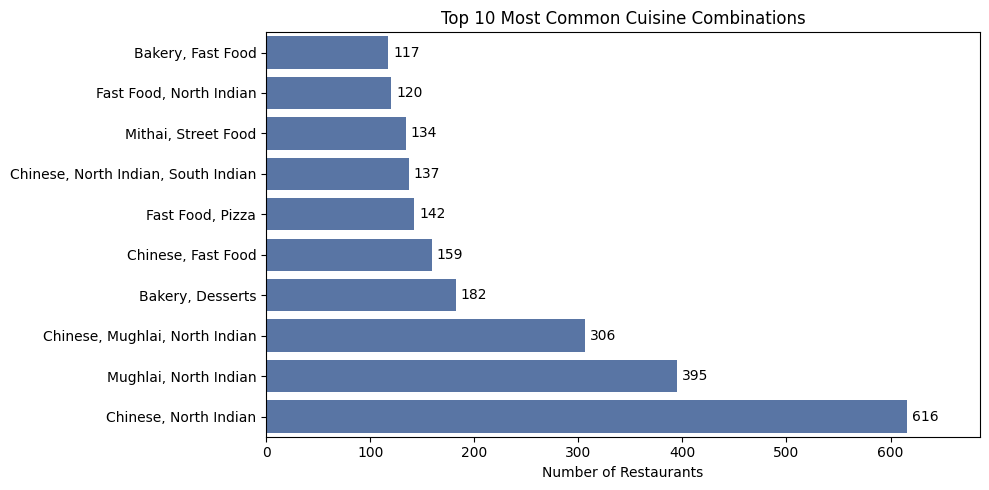

In [9]:
top10 = combo_counts.head(10).sort_values()

plt.figure(figsize=(10, 5))
ax = sns.barplot(x=top10.values, y=top10.index, color="#4C72B0")
for i, v in enumerate(top10.values):
    ax.text(v + 5, i, f"{v:,}", va="center")
plt.xlim(0, top10.max() + 70)
plt.title("Top 10 Most Common Cuisine Combinations")
plt.xlabel("Number of Restaurants")
plt.ylabel("")
plt.tight_layout()
plt.show()

Exact combinations are spread thin (over 1,200 different ones), so the pairs of
cuisines that appear together are also counted. A restaurant listing three
cuisines contributes three pairs.

In [10]:
pair_counter = Counter()
for cuisines in multi["Cuisine List"]:
    for pair in combinations(cuisines, 2):
        pair_counter[pair] += 1

top_pairs = pd.DataFrame(pair_counter.most_common(10), columns=["Cuisine Pair", "Restaurant Count"])
top_pairs["Cuisine Pair"] = top_pairs["Cuisine Pair"].apply(lambda p: " + ".join(p))
top_pairs

,Cuisine Pair,Restaurant Count
0,Chinese + North Indian,1782
1,Mughlai + North Indian,831
2,Fast Food + North Indian,485
3,Continental + North Indian,468
4,Chinese + Fast Food,466
5,North Indian + South Indian,405
6,Chinese + Mughlai,379
7,Chinese + South Indian,344
8,Chinese + Continental,303
9,Italian + North Indian,295


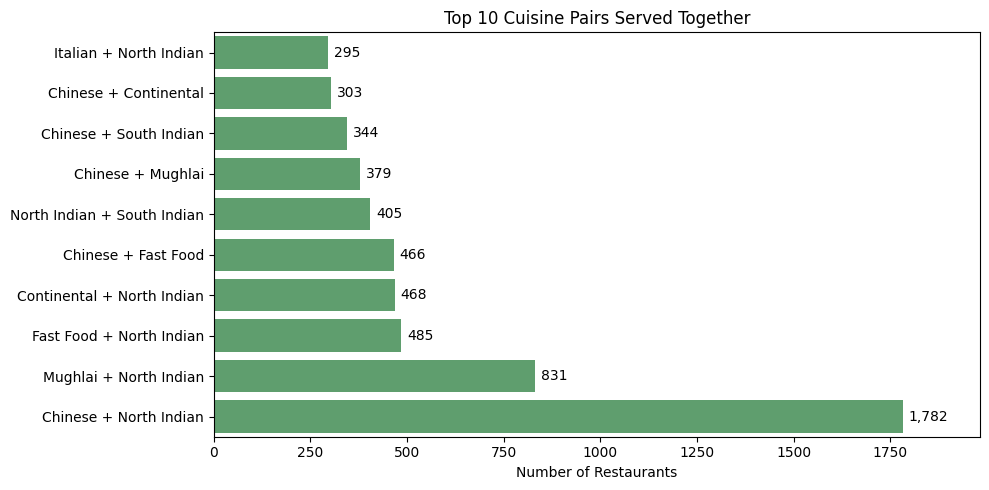

In [11]:
plot_pairs = top_pairs.sort_values("Restaurant Count")

plt.figure(figsize=(10, 5))
ax = sns.barplot(x=plot_pairs["Restaurant Count"], y=plot_pairs["Cuisine Pair"], color="#55A868")
for i, v in enumerate(plot_pairs["Restaurant Count"]):
    ax.text(v + 15, i, f"{v:,}", va="center")
plt.xlim(0, plot_pairs["Restaurant Count"].max() + 200)
plt.title("Top 10 Cuisine Pairs Served Together")
plt.xlabel("Number of Restaurants")
plt.ylabel("")
plt.tight_layout()
plt.show()

## 5. Do Some Combinations Get Higher Ratings?

Only rated restaurants (rating > 0) are used. A combination served by just a
few restaurants can top the list by chance, so combinations are ranked only if
they have at least **20 rated restaurants**.

In [12]:
rated_all = df_c[df_c["Aggregate rating"] > 0]
overall_avg = rated_all["Aggregate rating"].mean()
print(f"Rated restaurants: {len(rated_all):,} | Overall average rating: {overall_avg:.2f}")

rated_multi = multi[multi["Aggregate rating"] > 0]
combo_rating = (
    rated_multi.groupby("Combination")["Aggregate rating"]
    .agg(Avg_Rating="mean", Rated_Restaurants="count")
    .round(2)
)

MIN_RATED = 20
reliable = combo_rating[combo_rating["Rated_Restaurants"] >= MIN_RATED].sort_values("Avg_Rating", ascending=False)
print(f"Combinations meeting the threshold: {len(reliable)} of {len(combo_rating)}")

Rated restaurants: 7,394 | Overall average rating: 3.44
Combinations meeting the threshold: 33 of 1181


In [13]:
print("Highest-rated combinations:")
reliable.head(10)

Highest-rated combinations:


,Avg_Rating,Rated_Restaurants
Combination,,
"Japanese, Sushi",4.06,20
"Italian, Pizza",3.74,42
"Continental, Italian, North Indian",3.68,29
"Chinese, Continental, Italian, North Indian",3.61,37
"Continental, North Indian",3.58,38
"Chinese, Italian, North Indian",3.52,29
"Chinese, Thai",3.51,51
"Bakery, Desserts, Fast Food",3.47,66
"Burger, Fast Food",3.44,95


In [14]:
print("Lowest-rated combinations:")
reliable.tail(5)

Lowest-rated combinations:


,Avg_Rating,Rated_Restaurants
Combination,,
"Biryani, North Indian",3.06,26
"Fast Food, Pizza",3.03,121
"Chinese, South Indian",3.03,33
"American, Fast Food, Healthy Food, Salad",3.00,61
"Fast Food, Raw Meats",2.99,27


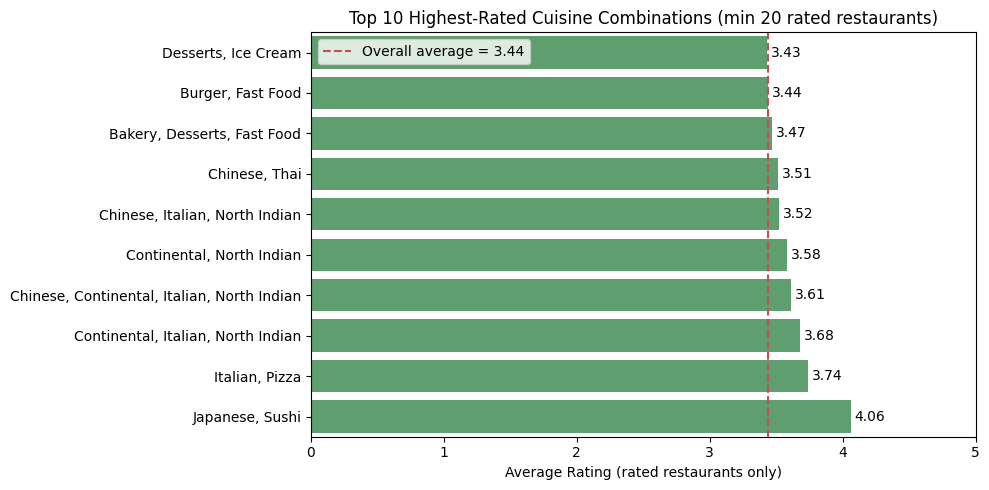

In [15]:
best = reliable.head(10).sort_values("Avg_Rating")

plt.figure(figsize=(10, 5))
ax = sns.barplot(x=best["Avg_Rating"], y=best.index, color="#55A868")
for i, v in enumerate(best["Avg_Rating"]):
    ax.text(v + 0.03, i, f"{v:.2f}", va="center")
plt.axvline(overall_avg, color="#C44E52", linestyle="--", label=f"Overall average = {overall_avg:.2f}")
plt.xlim(0, 5)
plt.title(f"Top 10 Highest-Rated Cuisine Combinations (min {MIN_RATED} rated restaurants)")
plt.xlabel("Average Rating (rated restaurants only)")
plt.ylabel("")
plt.legend()
plt.tight_layout()
plt.show()

### How do the most *common* combinations rate?

In [16]:
top_names = combo_counts.head(10).index
popular = combo_rating.reindex(top_names)
popular["Vs Overall Avg"] = (popular["Avg_Rating"] - overall_avg).round(2)
popular

,Avg_Rating,Rated_Restaurants,Vs Overall Avg
Combination,,,
"Chinese, North Indian",3.11,462,-0.33
"Mughlai, North Indian",3.28,332,-0.16
"Chinese, Mughlai, North Indian",3.11,258,-0.33
"Bakery, Desserts",3.41,127,-0.03
"Chinese, Fast Food",3.08,107,-0.36
"Fast Food, Pizza",3.03,121,-0.41
"Chinese, North Indian, South Indian",3.15,97,-0.29
"Mithai, Street Food",3.15,81,-0.29
"Fast Food, North Indian",3.20,90,-0.24


Most common combinations rated below the overall average: 10 of 10


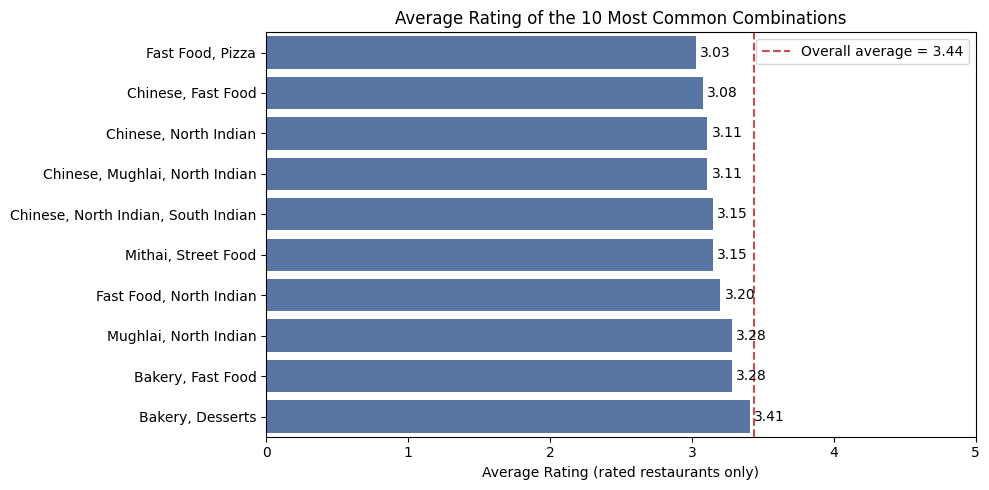

In [17]:
print(f"Most common combinations rated below the overall average: {(popular['Avg_Rating'] < overall_avg).sum()} of 10")

plot_pop = popular.sort_values("Avg_Rating")

plt.figure(figsize=(10, 5))
ax = sns.barplot(x=plot_pop["Avg_Rating"], y=plot_pop.index, color="#4C72B0")
for i, v in enumerate(plot_pop["Avg_Rating"]):
    ax.text(v + 0.03, i, f"{v:.2f}", va="center")
plt.axvline(overall_avg, color="#C44E52", linestyle="--", label=f"Overall average = {overall_avg:.2f}")
plt.xlim(0, 5)
plt.title("Average Rating of the 10 Most Common Combinations")
plt.xlabel("Average Rating (rated restaurants only)")
plt.ylabel("")
plt.legend()
plt.tight_layout()
plt.show()

### Does serving more cuisines help?

In [18]:
rated_all = rated_all.copy()
rated_all["Cuisine Count Group"] = rated_all["Num Cuisines"].clip(upper=4).map({1: "1", 2: "2", 3: "3", 4: "4+"})

by_count = (
    rated_all.groupby("Cuisine Count Group")["Aggregate rating"]
    .agg(Avg_Rating="mean", Rated_Restaurants="count")
    .round(2)
)
by_count

,Avg_Rating,Rated_Restaurants
Cuisine Count Group,,
1,3.40,2224
2,3.39,2739
3,3.49,1603
4+,3.61,828


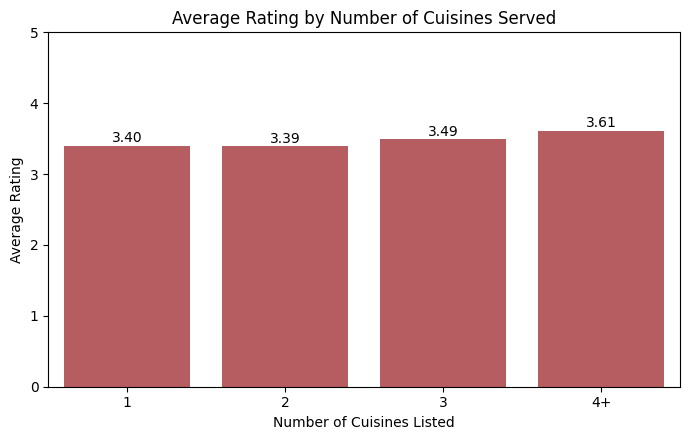

In [19]:
plt.figure(figsize=(7, 4.5))
ax = sns.barplot(x=by_count.index, y=by_count["Avg_Rating"], color="#C44E52")
for i, v in enumerate(by_count["Avg_Rating"]):
    ax.text(i, v + 0.05, f"{v:.2f}", ha="center")
plt.ylim(0, 5)
plt.title("Average Rating by Number of Cuisines Served")
plt.xlabel("Number of Cuisines Listed")
plt.ylabel("Average Rating")
plt.tight_layout()
plt.show()

### Robustness check 1: does the "best combination" depend on the minimum sample size?

In [20]:
sensitivity = []
for t in [20, 30, 50]:
    subset = combo_rating[combo_rating["Rated_Restaurants"] >= t].sort_values("Avg_Rating", ascending=False)
    sensitivity.append({
        "Min Rated Restaurants": t,
        "Combinations Ranked": len(subset),
        "Top Combination": subset.index[0],
        "Avg Rating": subset.iloc[0]["Avg_Rating"],
        "Rated Restaurants": int(subset.iloc[0]["Rated_Restaurants"]),
    })
pd.DataFrame(sensitivity)

,Min Rated Restaurants,Combinations Ranked,Top Combination,Avg Rating,Rated Restaurants
0,20,33,"Japanese, Sushi",4.06,20
1,30,25,"Italian, Pizza",3.74,42
2,50,17,"Chinese, Thai",3.51,51


### Robustness check 2: is it geography rather than cuisine?

Ratings are much higher outside India than inside India, so a combination that
is mostly served outside India can look "better" only because of location.

In [21]:
rated_all["Is India"] = rated_all["Currency"].str.contains("Indian")
print("Average rating, India:         ", round(rated_all[rated_all["Is India"]]["Aggregate rating"].mean(), 2))
print("Average rating, outside India: ", round(rated_all[~rated_all["Is India"]]["Aggregate rating"].mean(), 2))

rated_multi_c = rated_multi.assign(**{"Is India": rated_multi["Currency"].str.contains("Indian")})
india_share = rated_multi_c.groupby("Combination")["Is India"].mean().mul(100).round(0)

top_check = reliable.head(5).copy()
top_check["% Restaurants in India"] = india_share.reindex(top_check.index)
top_check

Average rating, India:          3.35
Average rating, outside India:  4.09


,Avg_Rating,Rated_Restaurants,% Restaurants in India
Combination,,,
"Japanese, Sushi",4.06,20,35.0
"Italian, Pizza",3.74,42,67.0
"Continental, Italian, North Indian",3.68,29,100.0
"Chinese, Continental, Italian, North Indian",3.61,37,100.0
"Continental, North Indian",3.58,38,100.0


In [22]:
india_multi = rated_multi_c[rated_multi_c["Is India"]]
india_rating = (
    india_multi.groupby("Combination")["Aggregate rating"]
    .agg(Avg_Rating="mean", Rated_Restaurants="count")
    .round(2)
)
india_reliable = india_rating[india_rating["Rated_Restaurants"] >= MIN_RATED].sort_values("Avg_Rating", ascending=False)

print(f"India-only combinations meeting the threshold: {len(india_reliable)}")
display(india_reliable.head(6))
display(india_reliable.tail(4))

India-only combinations meeting the threshold: 31


,Avg_Rating,Rated_Restaurants
Combination,,
"Continental, Italian, North Indian",3.68,29
"Chinese, Continental, Italian, North Indian",3.61,37
"Continental, North Indian",3.58,38
"Italian, Pizza",3.58,28
"Chinese, Italian, North Indian",3.52,29
"Chinese, Thai",3.49,49


,Avg_Rating,Rated_Restaurants
Combination,,
"Fast Food, Pizza",3.03,119
"Chinese, South Indian",3.03,33
"American, Fast Food, Healthy Food, Salad",3.00,61
"Fast Food, Raw Meats",2.99,27


### Robustness check 3: restaurants with vs without a given cuisine

In [23]:
rows = []
for cuisine in ["Italian", "Fast Food"]:
    for scope, data in [("All locations", rated_multi_c), ("India only", rated_multi_c[rated_multi_c["Is India"]])]:
        has = data["Cuisine List"].apply(lambda l: cuisine in l)
        rows.append({
            "Cuisine": cuisine,
            "Scope": scope,
            "Avg Rating (with)": round(data[has]["Aggregate rating"].mean(), 2),
            "Restaurants (with)": int(has.sum()),
            "Avg Rating (without)": round(data[~has]["Aggregate rating"].mean(), 2),
            "Restaurants (without)": int((~has).sum()),
        })
pd.DataFrame(rows)

,Cuisine,Scope,Avg Rating (with),Restaurants (with),Avg Rating (without),Restaurants (without)
0,Italian,All locations,3.73,676,3.41,4494
1,Italian,India only,3.70,618,3.32,3965
2,Fast Food,All locations,3.25,1335,3.53,3835
3,Fast Food,India only,3.25,1318,3.43,3265


## 6. Final Results

In [24]:
reliable_30 = combo_rating[combo_rating["Rated_Restaurants"] >= 30].sort_values("Avg_Rating", ascending=False)

task_result = pd.DataFrame({
    "Question": [
        "Most common cuisine combination",
        "Restaurants serving it",
        "Most common cuisine pair",
        "Highest-rated combination (min 20 rated)",
        "Highest-rated combination (min 30 rated)",
        "Highest-rated combination (India only, min 20 rated)",
        "Overall average rating (rated only)",
    ],
    "Answer": [
        combo_counts.index[0],
        f"{combo_counts.iloc[0]:,}",
        top_pairs.loc[0, "Cuisine Pair"],
        f"{reliable.index[0]} ({reliable.iloc[0]['Avg_Rating']:.2f})",
        f"{reliable_30.index[0]} ({reliable_30.iloc[0]['Avg_Rating']:.2f})",
        f"{india_reliable.index[0]} ({india_reliable.iloc[0]['Avg_Rating']:.2f})",
        f"{overall_avg:.2f}",
    ],
})
task_result

,Question,Answer
0,Most common cuisine combination,"Chinese, North Indian"
1,Restaurants serving it,616
2,Most common cuisine pair,Chinese + North Indian
3,Highest-rated combination (min 20 rated),"Japanese, Sushi (4.06)"
4,Highest-rated combination (min 30 rated),"Italian, Pizza (3.74)"
5,"Highest-rated combination (India only, min 20 ...","Continental, Italian, North Indian (3.68)"
6,Overall average rating (rated only),3.44


## 7. Validation

In [25]:
print("Rows used + missing cuisines = total:", len(df_c) + df["Cuisines"].isna().sum() == len(df))
print("Combination counts add up to multi-cuisine total:", combo_counts.sum() == len(multi))
print("Rated restaurants used for rating analysis:", len(rated_all))
print("Single-cuisine avg rating:", round(rated_all[rated_all["Num Cuisines"] == 1]["Aggregate rating"].mean(), 2))
print("Multi-cuisine avg rating: ", round(rated_all[rated_all["Num Cuisines"] > 1]["Aggregate rating"].mean(), 2))

Rows used + missing cuisines = total: True
Combination counts add up to multi-cuisine total: True
Rated restaurants used for rating analysis: 7394
Single-cuisine avg rating: 3.4
Multi-cuisine avg rating:  3.45


### Business Insights

**Market structure**

- **Most restaurants serve more than one cuisine.** 64.43% (6,148 of 9,542
  restaurants with a listed cuisine) offer two or more cuisines, while 35.57%
  offer just one. The market is also very varied: there are 1,245 different
  multi-cuisine combinations.
- **The most common combination is Chinese + North Indian**, served by **616
  restaurants (10.02% of multi-cuisine restaurants)**. It is followed by
  Mughlai + North Indian (395) and Chinese + Mughlai + North Indian (306).
  Bakery + Desserts (182) is the most common pairing built around desserts and
  snacks rather than main meals.
- **North Indian is the anchor cuisine.** It appears in 6 of the top 10
  cuisine pairs. Chinese + North Indian alone is served together by 1,782
  restaurants once restaurants with three or more cuisines are counted.

**Ratings of popular combinations**

- **Popular combinations are not the best rated.** All 10 of the most common
  combinations score below the overall average of 3.44 (by 0.03 to 0.41
  points). Fast Food + Pizza (3.03) and Chinese + Fast Food (3.08) are among the
  weakest of them, and Chinese + North Indian itself averages only 3.11.
- **Higher-rated combinations are rarer, but the "best" one is not reliable.**
  Among combinations with at least 20 rated restaurants, the highest are
  Japanese + Sushi (4.06), Italian + Pizza (3.74) and Continental + Italian +
  North Indian (3.68). However, the top spot changes with the minimum sample
  size (Japanese + Sushi at 20, Italian + Pizza at 30, Chinese + Thai at 50).
  Also, only 35% of Japanese + Sushi restaurants are in India, where ratings are
  lower (3.35) than outside India (4.09). Its high score may therefore reflect
  location rather than the cuisine mix.
- **Italian-based combinations hold up inside India too.** Within India alone,
  four of the top six combinations include Italian cuisine (best: Continental +
  Italian + North Indian, 3.68), so this pattern is more trustworthy than the
  single "best" combination.
- **Three of the five lowest-rated combinations involve fast food:** Fast Food
  + Raw Meats (2.99), American + Fast Food + Healthy Food + Salad (3.00) and
  Fast Food + Pizza (3.03). This also holds within India alone.

**Number of cuisines served**

- **Serving more cuisines helps only a little.** Average ratings are 3.40 for
  one cuisine, 3.39 for two, 3.49 for three and 3.61 for four or more. Overall,
  single-cuisine restaurants (3.40) and multi-cuisine restaurants (3.45) are
  almost identical, so a wider menu on its own does not guarantee better
  ratings.

**Takeaways**

- Pairing Chinese with North Indian is the safe, crowded choice. It is the most
  common combination, but its ratings (3.11) sit well below the overall average.
- Combinations with an Italian element rate higher: multi-cuisine restaurants
  serving Italian average 3.73 versus 3.41 without it (3.70 vs 3.32 within India
  alone). Fast food works the other way: 3.25 with fast food versus 3.53
  without it (3.25 vs 3.43 within India).

**Caution**

- Only 33 of 1,181 rated combinations have 20 or more rated restaurants, and
  the top ones have just 20 to 42 each, so rankings are indicative, not
  definitive.
- 9 restaurants without a listed cuisine and 2,148 unrated restaurants
  (rating 0, meaning "Not rated") are excluded from the rating comparison.
- The dataset is India-heavy (about 91% of listings), which is why Indian
  combinations dominate the counts.
- These results show association, not cause. They do not prove that a cuisine
  mix itself leads to better or worse ratings.